In [1]:
import xml.etree.ElementTree as ET
import random, math, copy
from datetime import date, timedelta

In [2]:
tree     = ET.parse("Full_Instance.xml")
root     = tree.getroot()
teams_el = root.find("Resources").find("Teams").findall("team")
n        = len(teams_el)
teams    = {int(t.attrib["id"]): t.attrib["name"] for t in teams_el}
T            = list(teams.keys())
SEASON_START = date(2024, 8, 10)
WINDOW_SIZE  = 3
K_WINDOW     = 3
S            = list(range(2*(n-1)))

In [3]:
dist = [[0]*n for _ in range(n)]
for trav in root.find("TravelMatrix").findall("Travel"):
    i = int(trav.attrib["home_team"]); j = int(trav.attrib["away_team"])
    dist[i][j] = int(trav.attrib["days"])

In [4]:
strengths = {}
for te in root.find("TeamStrengths").findall("Team"):
    strengths[int(te.attrib["id"])] = int(te.attrib["strength"])
 
print(f"Loaded {n} teams")
print("Loaded dist:", dist)
print("Loaded strengths:", strengths)

Loaded 6 teams
Loaded dist: [[0, 3, 1, 1, 3, 2], [3, 0, 1, 1, 1, 3], [1, 1, 0, 1, 3, 3], [1, 1, 1, 0, 3, 1], [3, 1, 3, 3, 0, 3], [2, 3, 3, 1, 3, 0]]
Loaded strengths: {0: 10, 1: 8, 2: 6, 3: 5, 4: 3, 5: 1}


In [5]:
# PART 2: 45 DATASET VARIATIONS — built FROM the loaded dist/strengths
# Short travel (1-2d), Medium (2-3d), Mixed (1-3d) x 5 seeds x Bal/Skw/Uni

def scale_dist(base, lo, hi, seed):
    """Rescale the loaded dist matrix into [lo,hi], keeping relative structure
    (closer real pairs stay closer, farther real pairs stay farther), with a
    small per-seed jitter so the 5 seeds within a range aren't identical."""
    random.seed(seed)  # fix RNG so this exact seed always reproduces the same matrix
 
    # flatten the upper triangle of the base matrix (it's symmetric, so we only
    # need i<j pairs) to find the real min/max travel days we're rescaling from
    flat = [base[i][j] for i in range(n) for j in range(i+1, n)]
    bmin, bmax = min(flat), max(flat)
 
    d = [[0]*n for _ in range(n)]
    for i in range(n):
        for j in range(i+1, n):
            if bmax == bmin:
                # every real pair had the same distance -> nothing to scale from,
                # just pick uniformly inside the target range
                v = random.randint(lo, hi)
            else:
                # normalize this pair's real distance to a 0-1 fraction of the
                # real min/max range, then map that fraction onto [lo,hi] so a
                # pair that was relatively far in the real data stays relatively
                # far here too
                frac = (base[i][j] - bmin) / (bmax - bmin)
                v = round(lo + frac*(hi-lo))
                # add a small +/-1 jitter (biased towards 0 via the extra "0" in
                # the choice list) so different seeds aren't all identical, then
                # clamp back into [lo,hi]
                v = max(lo, min(hi, v + random.choice([-1,0,0,1])))
            d[i][j] = v; d[j][i] = v  # keep matrix symmetric
    return d

In [6]:
def perturb_strengths(base, profile, seed):
    """Reassign the loaded strengths (keeping the REAL strongest->weakest team
    order) onto the target shape for that profile (Balanced/Skewed/Uniform)."""
    # rank teams strongest -> weakest using their REAL loaded strength values;
    # this order is preserved regardless of profile, only the numeric values change
    order = sorted(base, key=lambda t: -base[t])
 
    # each profile defines a target distribution shape (already sorted desc):
    # Bal = spread evenly strong to weak, Skw = few very strong + rest weak,
    # Uni = everyone close together
    targets = {
        "Bal": [10,8,6,5,3,1],
        "Skw": [10,9,8,2,1,1],
        "Uni": [6,6,6,5,5,5],
    }[profile]
 
    # targets list is hardcoded for 6 teams -> trim or pad (repeat last value)
    # so this still works if the loaded instance has a different team count
    vals = targets[:n] if n <= len(targets) else targets + [targets[-1]]*(n-len(targets))
 
    # rank 0 (strongest real team) gets vals[0] (highest target value), etc.
    # -> real ranking order is kept, only the magnitude is reshaped per profile
    return {tid: vals[rank] for rank, tid in enumerate(order)}

In [7]:
# (range_tag, lo_days, hi_days, seed_offset)
# offset just keeps Sht/Med/Uni seed sequences from colliding (seed 1 for Sht
# is different randomness than seed 1 for Med, etc.), it has no other meaning
_ranges = [("Sht",1,2,0), ("Med",2,3,5), ("Mix",1,3,10)]

In [8]:
datasets = []
for tag, lo, hi, offset in _ranges:               # loop travel-range variants
    for si, seed in enumerate(range(1,6), start=1):    # 5 seeds per range
        for profile in ["Bal","Skw","Uni"]:            # 3 strength shapes per seed
            # -> 3 ranges x 5 seeds x 3 profiles = 45 datasets total, each one
            # a (name, distance_matrix, strengths_dict) tuple built from the
            # single real dist/strengths loaded in Part 1
            datasets.append((
                f"{tag}_S{si}_{profile}",
                scale_dist(dist, lo, hi, seed+offset),
                perturb_strengths(strengths, profile, seed+offset)
            ))

In [9]:
# PART 3: SA PARAMETER CONFIGURATIONS

params = [
    {"label":"P1 T500  c0.995 i3k", "T_start":500,  "T_end":0.1, "cooling":0.995, "max_iter":3000},
    {"label":"P2 T1000 c0.995 i3k", "T_start":1000, "T_end":0.1, "cooling":0.995, "max_iter":3000},
    {"label":"P3 T500  c0.990 i3k", "T_start":500,  "T_end":0.1, "cooling":0.990, "max_iter":3000},
    {"label":"P4 T500  c0.995 i5k", "T_start":500,  "T_end":0.1, "cooling":0.995, "max_iter":5000},
    {"label":"P5 T200  c0.995 i3k", "T_start":200,  "T_end":0.1, "cooling":0.995, "max_iter":3000},
    {"label":"P6 T2000 c0.998 i5k", "T_start":2000, "T_end":0.1, "cooling":0.998, "max_iter":5000},
    {"label":"P7 T100  c0.999 i8k", "T_start":100,  "T_end":0.05,"cooling":0.999, "max_iter":8000},
    {"label":"P8 T800  c0.980 i2k", "T_start":800,  "T_end":0.1, "cooling":0.980, "max_iter":2000},
    {"label":"P9 T1500 c0.992 i10k","T_start":1500, "T_end":0.1, "cooling":0.992, "max_iter":10000},
    {"label":"P10 T50  c0.995 i3k", "T_start":50,   "T_end":0.01,"cooling":0.995, "max_iter":3000},
]
 

print(f"Datasets: {len(datasets)} | Params: {len(params)} | Total runs: {len(datasets)*len(params)}")

Datasets: 45 | Params: 10 | Total runs: 450


In [10]:
# PART 4: INITIAL SCHEDULE — circle method double round robin

def circle_method(n):
    rot=list(range(n)); rounds=[]
    for _ in range(n-1):
        rnd=[(rot[0],rot[n-1])]+[(rot[i],rot[n-1-i]) for i in range(1,n//2)]
        rounds.append(rnd)
        rot=[rot[0]]+[rot[-1]]+rot[1:-1]
    return rounds
 
fh=circle_method(n)
sh=[[(a,h) for h,a in rnd] for rnd in fh]
all_rounds=fh+sh

In [11]:
def make_schedule():
    sched=[]
    for si,rnd in enumerate(all_rounds):
        ws=SEASON_START+timedelta(days=si*WINDOW_SIZE)
        we=ws+timedelta(days=WINDOW_SIZE-1)
        for gi,(h,a) in enumerate(rnd):
            sched.append({"slot":si,"home":h,"home_name":teams[h],
                          "away":a,"away_name":teams[a],
                          "date":ws+timedelta(days=gi),
                          "window_start":ws,"window_end":we})
    return sched

In [12]:
# PART 5: PENALTY FUNCTION

def penalty(sc, dist, st):
    """Total penalty score for a schedule `sc` (lower = better). Hard
    constraints (H1/H3/H4/H5) each add a large fixed 999 per violation so SA
    strongly avoids infeasible schedules; soft constraints (S5/S6) add a
    smaller, proportional penalty so SA can trade them off for a better fit."""
    tot=0; slots=sorted(set(g["slot"] for g in sc))
    DM=2*sum(st.values())/n  # difficulty max: 2x average team strength, the
                              # ceiling used by S6 for "too many strong opponents bunched up"
 
    # H1: round balance — every team must play exactly once in each slot
    # (no team idle, no team double-booked in the same slot)
    for s in slots:
        sg=[g for g in sc if g["slot"]==s]
        at=[g["home"] for g in sg]+[g["away"] for g in sg]
        for t in T:
            if at.count(t)!=1: tot+=999
 
    # H3: travel feasibility — for each team's consecutive games (sorted by
    # date), the gap in days must be enough to (a) travel home if they were
    # away, and (b) travel to the next venue if the next game is away
    for t in T:
        tg=sorted([g for g in sc if g["home"]==t or g["away"]==t],key=lambda g:g["date"])
        for i in range(len(tg)-1):
            gap=(tg[i+1]["date"]-tg[i]["date"]).days
            rh=dist[tg[i]["home"]][t] if tg[i]["away"]==t else 0     # return-home travel time
            tr=dist[tg[i+1]["home"]][t] if tg[i+1]["away"]==t else 0 # travel-to-next-game time
            if gap<rh+tr: tot+=999
 
    # H4: double round robin integrity — each ordered fixture (i home, j away)
    # must appear exactly once across the whole schedule
    for i in T:
        for j in T:
            if i!=j and sum(1 for g in sc if g["home"]==i and g["away"]==j)!=1: tot+=999
 
    # H5: home/away balance — at any point in the season, a team's cumulative
    # home-game count and away-game count can't differ by more than 1
    for t in T:
        for s in slots:
            ch=sum(1 for g in sc if g["slot"]<=s and g["home"]==t)
            ca=sum(1 for g in sc if g["slot"]<=s and g["away"]==t)
            if abs(ch-ca)>1: tot+=999
 
    # S5 (soft): rest day — teams should get at least 1 day off between
    # games; penalty scales with how many days short they are
    for t in T:
        tg=sorted([g for g in sc if g["home"]==t or g["away"]==t],key=lambda g:g["date"])
        for i in range(len(tg)-1):
            gap=(tg[i+1]["date"]-tg[i]["date"]).days
            if gap<1: tot+=(1-gap)
 
    # S6 (soft): difficulty spacing — within any rolling K_WINDOW-slot window,
    # sum of opponent strengths a team faces shouldn't exceed DM (2x avg
    # strength); penalty scales with how far over that ceiling they go, x5
    for t in T:
        for s in slots:
            ws=[x for x in slots if s<=x<=s+K_WINDOW-1]
            if len(ws)<K_WINDOW: continue  # skip windows that run past the season end
            ts=sum(st[g["away"] if g["home"]==t else g["home"]]
                   for g in sc if g["slot"] in ws and (g["home"]==t or g["away"]==t))
            if ts>DM: tot+=(ts-DM)*5
    return tot

In [13]:
def det_penalty(sc, dist, st):
    slots=sorted(set(g["slot"] for g in sc)); DM=2*sum(st.values())/n; r={}
    h1=sum(1 for s in slots for t in T
           if [g["home"] for g in sc if g["slot"]==s].count(t)+
              [g["away"] for g in sc if g["slot"]==s].count(t)!=1)
    r["H1"]={"v":h1,"p":h1*999}
    h3=0
    for t in T:
        tg=sorted([g for g in sc if g["home"]==t or g["away"]==t],key=lambda g:g["date"])
        for i in range(len(tg)-1):
            gap=(tg[i+1]["date"]-tg[i]["date"]).days
            rh=dist[tg[i]["home"]][t] if tg[i]["away"]==t else 0
            tr=dist[tg[i+1]["home"]][t] if tg[i+1]["away"]==t else 0
            if gap<rh+tr: h3+=1
    r["H3"]={"v":h3,"p":h3*999}
    h4=sum(1 for i in T for j in T if i!=j
           if sum(1 for g in sc if g["home"]==i and g["away"]==j)!=1)
    r["H4"]={"v":h4,"p":h4*999}
    h5=sum(1 for t in T for s in slots
           if abs(sum(1 for g in sc if g["slot"]<=s and g["home"]==t)-
                  sum(1 for g in sc if g["slot"]<=s and g["away"]==t))>1)
    r["H5"]={"v":h5,"p":h5*999}
    s5v=s5p=0
    for t in T:
        tg=sorted([g for g in sc if g["home"]==t or g["away"]==t],key=lambda g:g["date"])
        for i in range(len(tg)-1):
            gap=(tg[i+1]["date"]-tg[i]["date"]).days
            if gap<1: s5v+=1;s5p+=(1-gap)
    r["S5"]={"v":s5v,"p":s5p}
    s6v=s6p=0
    for t in T:
        for s in slots:
            ws=[x for x in slots if s<=x<=s+K_WINDOW-1]
            if len(ws)<K_WINDOW: continue
            ts=sum(st[g["away"] if g["home"]==t else g["home"]]
                   for g in sc if g["slot"] in ws and (g["home"]==t or g["away"]==t))
            if ts>DM: s6v+=1;s6p+=(ts-DM)*5
    r["S6"]={"v":s6v,"p":s6p}
    return r

In [14]:
# PART 6: SA MOVES

def swap_games(sc):
    """Move one game from slot s1 into slot s2 and vice versa (swaps their
    slot/window/date), but only if doing so doesn't put a team in two games
    in the same slot -> keeps H1 satisfiable most of the time."""
    new=copy.deepcopy(sc); s1,s2=random.sample(S,2)  # pick 2 distinct slots at random
    g1o=[g for g in new if g["slot"]==s1]; g2o=[g for g in new if g["slot"]==s2]
    if not g1o or not g2o: return new  # safety guard, shouldn't normally trigger
    g1=random.choice(g1o); g2=random.choice(g2o)
 
    # teams already occupying the OTHER slot (excluding the game being swapped in)
    s2t=([g["home"] for g in new if g["slot"]==s2 and g!=g2]+
         [g["away"] for g in new if g["slot"]==s2 and g!=g2])
    s1t=([g["home"] for g in new if g["slot"]==s1 and g!=g1]+
         [g["away"] for g in new if g["slot"]==s1 and g!=g1])
    # reject the swap if it would double-book a team in a slot
    if g1["home"] in s2t or g1["away"] in s2t: return new
    if g2["home"] in s1t or g2["away"] in s1t: return new
 
    # perform the swap: exchange slot number, window dates, and the actual date
    g1["slot"],g2["slot"]=g2["slot"],g1["slot"]
    g1["window_start"],g2["window_start"]=g2["window_start"],g1["window_start"]
    g1["window_end"],g2["window_end"]=g2["window_end"],g1["window_end"]
    g1["date"],g2["date"]=g2["date"],g1["date"]
    return new

In [15]:
def flip_random(sc):
    """Flip home/away for one random game, unless the reverse fixture
    (same two teams, opposite venue) already exists elsewhere -> avoids
    trivially breaking H4 (each ordered fixture must appear exactly once)."""
    new=copy.deepcopy(sc); g=random.choice(new)
    rev=any(x["home"]==g["away"] and x["away"]==g["home"] for x in new if x!=g)
    if not rev:
        g["home"],g["away"]=g["away"],g["home"]
        g["home_name"],g["away_name"]=g["away_name"],g["home_name"]
    return new

In [16]:
def shift_date(sc):
    """Move one random game to a different day within its own slot window
    (doesn't change which slot it's in, just the exact date inside it) ->
    used to help satisfy H3/S5 travel/rest spacing without touching H1/H4/H5."""
    new=copy.deepcopy(sc); g=random.choice(new)
    days=(g["window_end"]-g["window_start"]).days+1
    g["date"]=g["window_start"]+timedelta(days=random.randint(0,days-1))
    return new

In [17]:
# PART 7: SA V1 RUNNER

def run_sa_v1(sc, dist, st, T_start, T_end, cooling, max_iter):
    """Standard simulated annealing loop.
    cur/cs = current schedule/score being walked (can get worse temporarily).
    best/bs = best schedule/score ever seen (only ever improves, this is what
    we return at the end)."""
    cur=copy.deepcopy(sc); cs=penalty(cur,dist,st)
    best=copy.deepcopy(cur); bs=cs; T=T_start  # start temperature high -> more exploration early on
    for _ in range(max_iter):
        nb=random.choice([swap_games,flip_random,shift_date])(cur)  # random neighbor move
        ns=penalty(nb,dist,st); d=ns-cs  # d = change in penalty (negative = improvement)
 
        # always accept improving moves; accept worsening moves with
        # probability exp(-d/T) so SA can escape local minima -> probability
        # shrinks as T cools, so late in the run only improvements are accepted
        if d<0 or random.random()<math.exp(-d/T): cur=nb;cs=ns
 
        if cs<bs: best=copy.deepcopy(cur);bs=cs  # track best-ever separately from current walk
 
        T=max(T*cooling,T_end)  # geometric cooling, floor at T_end so exp() never explodes
    return best,bs

In [18]:
# PART 8: MAIN RUN LOOP

print("\n"+"="*100)
print("SA V1 — 45 DATASETS x 5 PARAMETER CONFIGS")
print("="*100)
print(f"{'Dataset':<22} {'Baseline':>10} | "+
      " | ".join(f"{p['label'][:18]:>18}" for p in params))
print("-"*100)
 
results = []
 
for name, d_, st in datasets:
    random.seed(42)
    init  = make_schedule()
    base  = penalty(init, d_, st)
    row   = {"name": name, "baseline": base, "params": {}}
 
    for p in params:
        random.seed(42)
        best_sc, best_score = run_sa_v1(
            init, d_, st,
            p["T_start"], p["T_end"], p["cooling"], p["max_iter"]
        )
        det = det_penalty(best_sc, d_, st)
        imp = (base - best_score) / base * 100 if base else 0
        row["params"][p["label"]] = {
            "score":   best_score,
            "improve": imp,
            "detail":  det
        }
 
    results.append(row)
 
    scores = [f"{row['params'][p['label']]['score']:>18.0f}" for p in params]
    print(f"{name:<22} {base:>10.0f} | " + " | ".join(scores))
 
print("="*100)


SA V1 — 45 DATASETS x 5 PARAMETER CONFIGS
Dataset                  Baseline | P1 T500  c0.995 i3 | P2 T1000 c0.995 i3 | P3 T500  c0.990 i3 | P4 T500  c0.995 i5 | P5 T200  c0.995 i3 | P6 T2000 c0.998 i5 | P7 T100  c0.999 i8 | P8 T800  c0.980 i2 | P9 T1500 c0.992 i1 | P10 T50  c0.995 i3
----------------------------------------------------------------------------------------------------
Sht_S1_Bal                  27329 |               9347 |               9347 |               9347 |               7349 |               9347 |               7349 |               5351 |               9347 |               5351 |               9347
Sht_S1_Skw                  27282 |               9300 |               9300 |               9300 |               7302 |               9300 |               7302 |               5304 |               9300 |               5304 |               9300
Sht_S1_Uni                  27294 |               9312 |               9312 |               9312 |               7314 |     

In [19]:
# PART 9: SUMMARY STATS

print("\nAVERAGE IMPROVEMENT PER PARAMETER CONFIG:")
print("-"*70)
for p in params:
    ai  = sum(r["params"][p["label"]]["improve"]         for r in results) / len(results)
    ah3 = sum(r["params"][p["label"]]["detail"]["H3"]["v"] for r in results) / len(results)
    ah5 = sum(r["params"][p["label"]]["detail"]["H5"]["v"] for r in results) / len(results)
    print(f"  {p['label']:<25} improve:{ai:.1f}%  avg H3:{ah3:.1f}  avg H5:{ah5:.1f}")
 
print("\nBEST PARAMETER PER DATASET:")
print("-"*70)
for r in results:
    best_p  = min(r["params"], key=lambda k: r["params"][k]["score"])
    best_sc = r["params"][best_p]["score"]
    best_im = r["params"][best_p]["improve"]
    print(f"  {r['name']:<22} -> {best_p} | score:{best_sc:.0f} | improve:{best_im:.1f}%")


AVERAGE IMPROVEMENT PER PARAMETER CONFIG:
----------------------------------------------------------------------
  P1 T500  c0.995 i3k       improve:62.2%  avg H3:2.8  avg H5:8.2
  P2 T1000 c0.995 i3k       improve:60.0%  avg H3:2.9  avg H5:8.7
  P3 T500  c0.990 i3k       improve:62.2%  avg H3:2.8  avg H5:8.2
  P4 T500  c0.995 i5k       improve:71.9%  avg H3:2.4  avg H5:5.6
  P5 T200  c0.995 i3k       improve:62.2%  avg H3:2.8  avg H5:8.2
  P6 T2000 c0.998 i5k       improve:67.6%  avg H3:2.3  avg H5:7.1
  P7 T100  c0.999 i8k       improve:73.0%  avg H3:2.3  avg H5:5.3
  P8 T800  c0.980 i2k       improve:61.3%  avg H3:2.9  avg H5:8.5
  P9 T1500 c0.992 i10k      improve:74.1%  avg H3:2.2  avg H5:5.1
  P10 T50  c0.995 i3k       improve:62.2%  avg H3:2.8  avg H5:8.2

BEST PARAMETER PER DATASET:
----------------------------------------------------------------------
  Sht_S1_Bal             -> P7 T100  c0.999 i8k | score:5351 | improve:80.4%
  Sht_S1_Skw             -> P7 T100  c0.999 i8k |

In [20]:
print("\nAVERAGE IMPROVEMENT BY TRAVEL RANGE:")
print("-"*70)
for grp_name in ["Sht", "Med", "Mix"]:
    grp = [r for r in results if r["name"].startswith(grp_name)]
    best_ai = max(
        sum(r["params"][p["label"]]["improve"] for r in grp) / len(grp)
        for p in params
    )
    label = {"Sht":"Short (1-2d)","Med":"Medium (2-3d)","Mix":"Mixed (1-3d)"}[grp_name]
    print(f"  {label:<20} best avg improvement: {best_ai:.1f}%")


AVERAGE IMPROVEMENT BY TRAVEL RANGE:
----------------------------------------------------------------------
  Short (1-2d)         best avg improvement: 79.0%
  Medium (2-3d)        best avg improvement: 73.2%
  Mixed (1-3d)         best avg improvement: 70.2%


In [21]:
print("\nAVERAGE IMPROVEMENT BY STRENGTH PROFILE:")
print("-"*70)
for prof in ["Bal","Skw","Uni"]:
    grp = [r for r in results if prof in r["name"]]
    best_ai = max(
        sum(r["params"][p["label"]]["improve"] for r in grp) / len(grp)
        for p in params
    )
    label = {"Bal":"Balanced","Skw":"Skewed","Uni":"Uniform"}[prof]
    print(f"  {label:<20} best avg improvement: {best_ai:.1f}%")


AVERAGE IMPROVEMENT BY STRENGTH PROFILE:
----------------------------------------------------------------------
  Balanced             best avg improvement: 74.1%
  Skewed               best avg improvement: 74.2%
  Uniform              best avg improvement: 74.2%


In [22]:
print("\nDETAILED CONSTRAINT BREAKDOWN — BEST PARAM PER DATASET:")
print("="*100)
print(f"{'Dataset':<22} {'Baseline':>10} {'Best Score':>11} {'Improve%':>9} "
      f"{'H1':>5} {'H3':>5} {'H4':>5} {'H5':>5} {'S5':>5} {'S6':>5} {'Best Param':>20}")
print("-"*100)
for r in results:
    best_p  = min(r["params"], key=lambda k: r["params"][k]["score"])
    d       = r["params"][best_p]
    det     = d["detail"]
    print(f"{r['name']:<22} {r['baseline']:>10.0f} {d['score']:>11.0f} "
          f"{d['improve']:>8.1f}% "
          f"{det['H1']['v']:>5} {det['H3']['v']:>5} {det['H4']['v']:>5} "
          f"{det['H5']['v']:>5} {det['S5']['v']:>5} {det['S6']['v']:>5} "
          f"{best_p:>20}")
print("="*100)


DETAILED CONSTRAINT BREAKDOWN — BEST PARAM PER DATASET:
Dataset                  Baseline  Best Score  Improve%    H1    H3    H4    H5    S5    S6           Best Param
----------------------------------------------------------------------------------------------------
Sht_S1_Bal                  27329        5351     80.4%     0     0     0     4     0    43  P7 T100  c0.999 i8k
Sht_S1_Skw                  27282        5304     80.6%     0     0     0     4     0    43  P7 T100  c0.999 i8k
Sht_S1_Uni                  27294        5316     80.5%     0     0     0     4     0    48  P7 T100  c0.999 i8k
Sht_S2_Bal                  27329        5351     80.4%     0     0     0     4     0    43  P4 T500  c0.995 i5k
Sht_S2_Skw                  27282        5304     80.6%     0     0     0     4     0    43  P4 T500  c0.995 i5k
Sht_S2_Uni                  27294        5316     80.5%     0     0     0     4     0    48  P4 T500  c0.995 i5k
Sht_S3_Bal                  26330        5351     7

In [23]:
import matplotlib.pyplot as plt
import numpy as np

In [24]:
colors  = ["#2196F3","#4CAF50","#FF9800","#E91E63","#9C27B0"]
names   = [r["name"] for r in results]
x       = np.arange(len(results))

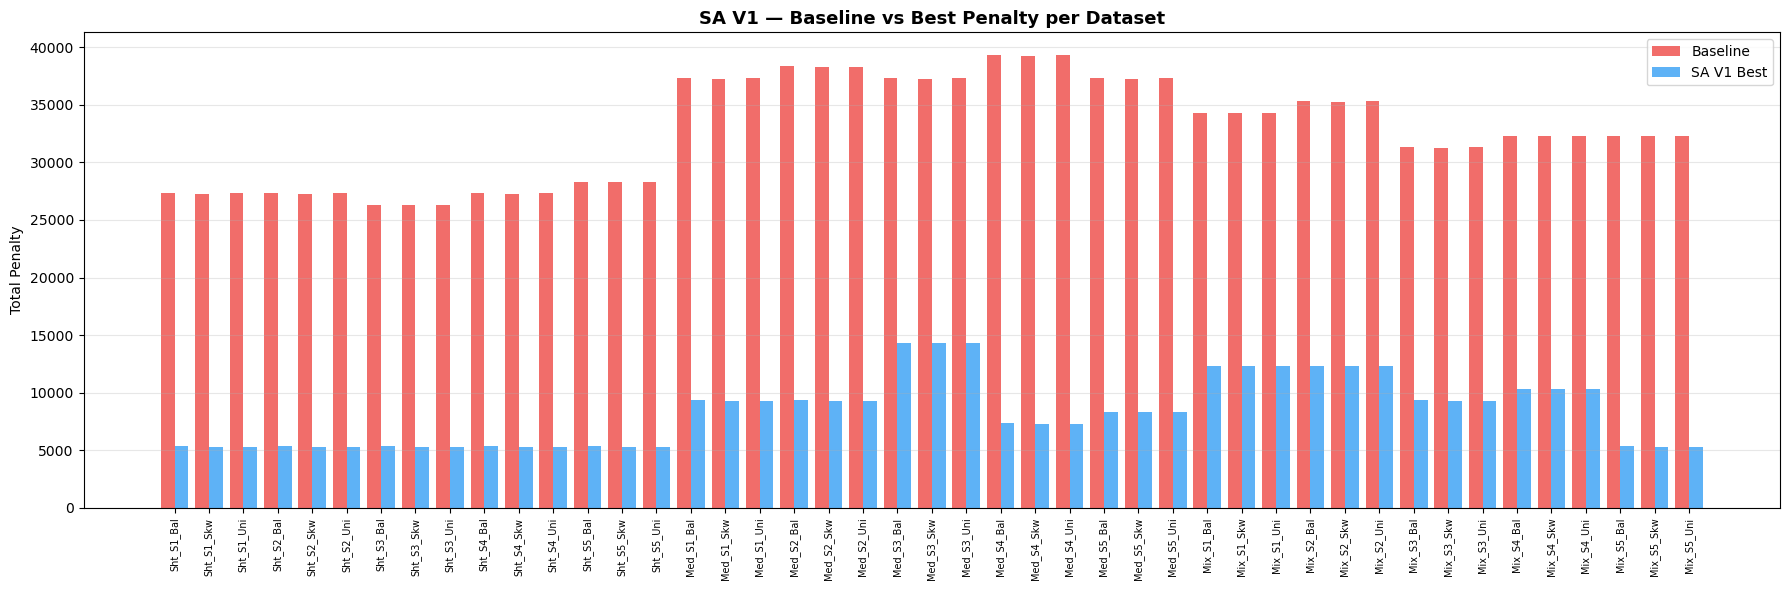

In [25]:
# GRAPH 1: Baseline vs Best SA penalty per dataset
fig, ax = plt.subplots(figsize=(18, 6))
base_vals = [r["baseline"] for r in results]
best_vals = [min(r["params"][p["label"]]["score"] for p in params) for r in results]
ax.bar(x - 0.2, base_vals, 0.4, label="Baseline",    color="#EF5350", alpha=0.85)
ax.bar(x + 0.2, best_vals, 0.4, label="SA V1 Best",  color="#42A5F5", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=7)
ax.set_title("SA V1 — Baseline vs Best Penalty per Dataset", fontsize=13, fontweight="bold")
ax.set_ylabel("Total Penalty"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

IndexError: list index out of range

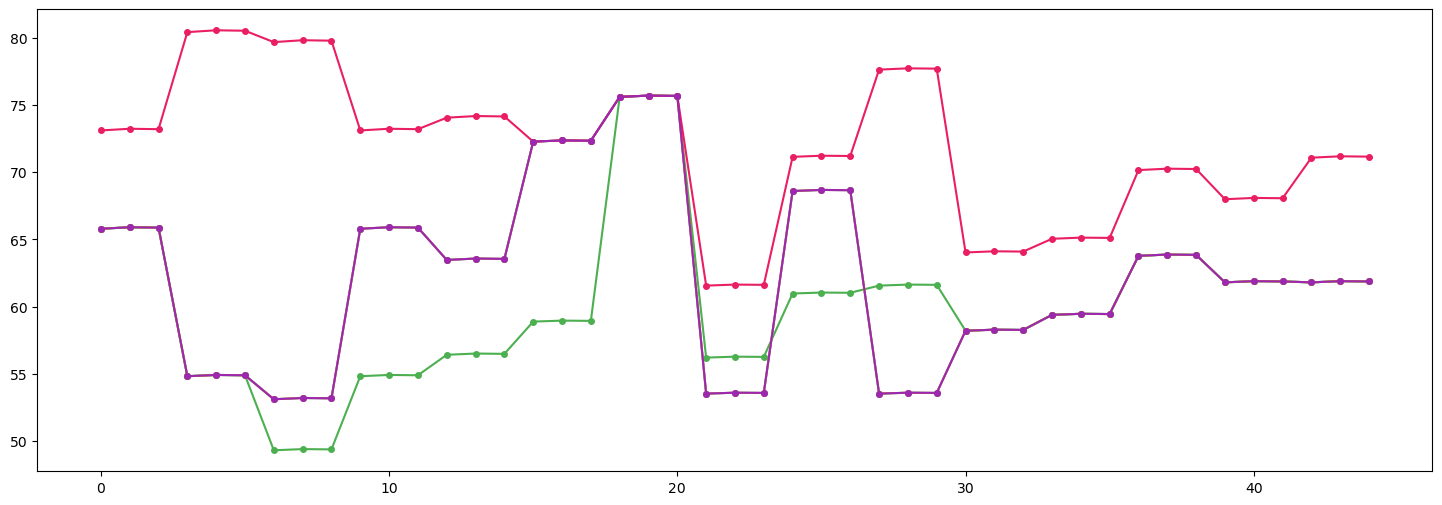

In [26]:
# GRAPH 2: Improvement % per parameter config per dataset
fig, ax = plt.subplots(figsize=(18, 6))
for idx, p in enumerate(params):
    imps = [r["params"][p["label"]]["improve"] for r in results]
    ax.plot(x, imps, marker="o", markersize=4, label=p["label"], color=colors[idx], linewidth=1.5)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=7)
ax.set_title("SA V1 — Improvement % per Parameter Config", fontsize=13, fontweight="bold")
ax.set_ylabel("Improvement %"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


IndexError: list index out of range

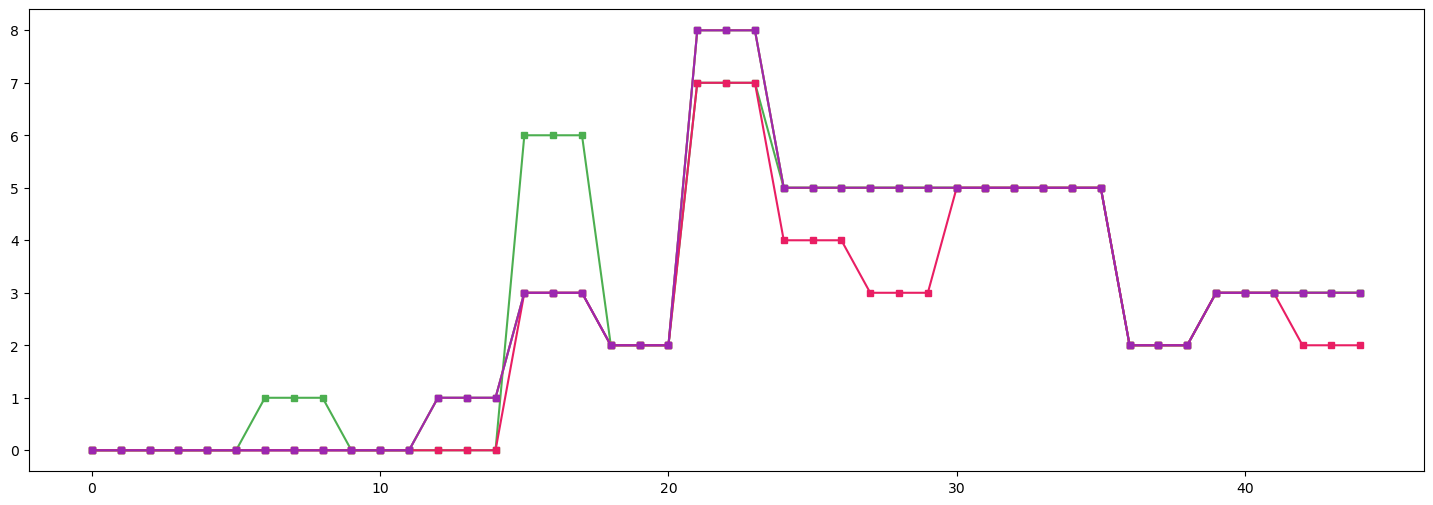

In [27]:
# GRAPH 3: H3 violations after SA per parameter config
fig, ax = plt.subplots(figsize=(18, 6))
for idx, p in enumerate(params):
    h3 = [r["params"][p["label"]]["detail"]["H3"]["v"] for r in results]
    ax.plot(x, h3, marker="s", markersize=4, label=p["label"], color=colors[idx], linewidth=1.5)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=7)
ax.set_title("SA V1 — H3 Travel Violations After SA", fontsize=13, fontweight="bold")
ax.set_ylabel("H3 Violations"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

IndexError: list index out of range

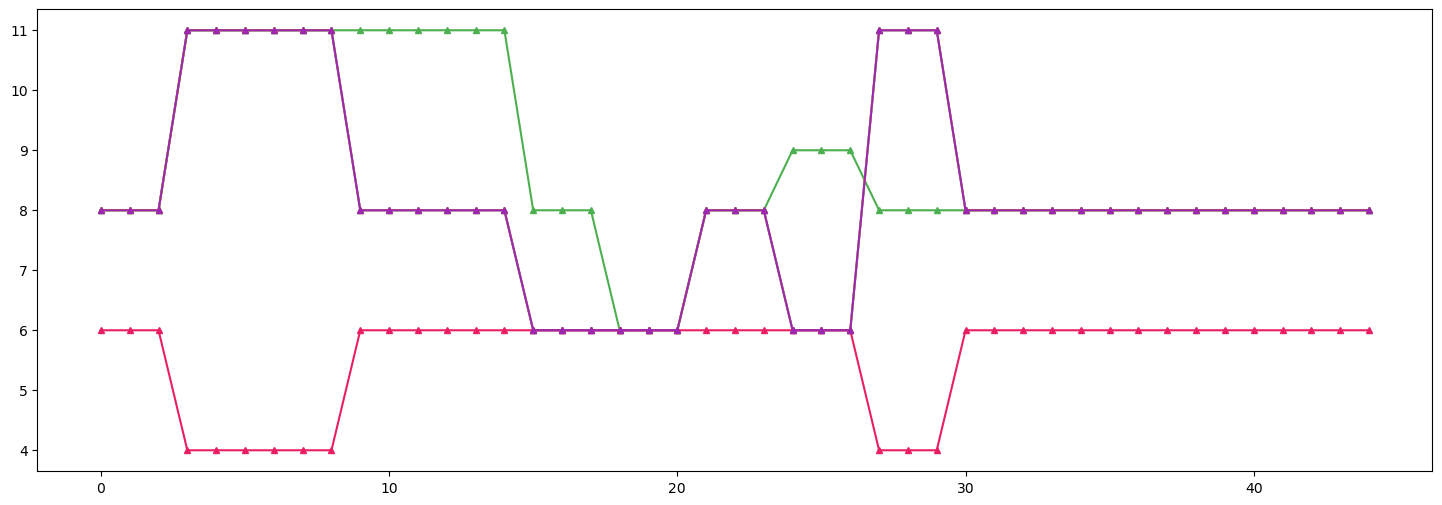

In [28]:
# GRAPH 4: H5 violations after SA per parameter config
fig, ax = plt.subplots(figsize=(18, 6))
for idx, p in enumerate(params):
    h5 = [r["params"][p["label"]]["detail"]["H5"]["v"] for r in results]
    ax.plot(x, h5, marker="^", markersize=4, label=p["label"], color=colors[idx], linewidth=1.5)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=7)
ax.set_title("SA V1 — H5 Home Away Balance Violations After SA", fontsize=13, fontweight="bold")
ax.set_ylabel("H5 Violations"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

IndexError: list index out of range

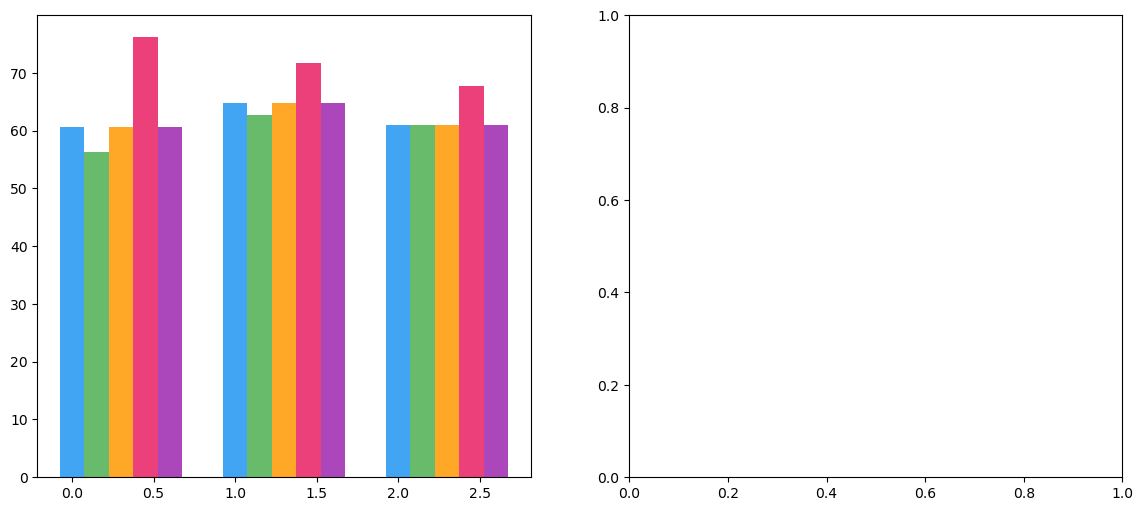

In [29]:
# GRAPH 5: Average improvement by travel range and strength profile
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
grp_names, grp_labels = ["Sht","Med","Mix"], ["Short (1-2d)","Medium (2-3d)","Mixed (1-3d)"]
for idx, p in enumerate(params):
    avgs = [sum(r["params"][p["label"]]["improve"] for r in results if r["name"].startswith(g)) /
            len([r for r in results if r["name"].startswith(g)]) for g in grp_names]
    axes[0].bar(np.arange(3) + idx*0.15, avgs, 0.15, label=p["label"][:10], color=colors[idx], alpha=0.85)
axes[0].set_xticks(np.arange(3)+0.3); axes[0].set_xticklabels(grp_labels)
axes[0].set_title("Avg Improvement by Travel Range", fontweight="bold")
axes[0].set_ylabel("Improvement %"); axes[0].legend(fontsize=7); axes[0].grid(axis="y", alpha=0.3)

prof_names, prof_labels = ["Bal","Skw","Uni"], ["Balanced","Skewed","Uniform"]
for idx, p in enumerate(params):
    avgs = []
    for pr in prof_names:
        matches = [r for r in results if pr in r["name"]]
        avgs.append(sum(r["params"][p["label"]]["improve"] for r in matches) / len(matches) if matches else 0)
    axes[1].bar(np.arange(3) + idx*0.15, avgs, 0.15, label=p["label"][:10], color=colors[idx], alpha=0.85)
axes[1].set_xticks(np.arange(3)+0.3); axes[1].set_xticklabels(prof_labels)
axes[1].set_title("Avg Improvement by Strength Profile", fontweight="bold")
axes[1].set_ylabel("Improvement %"); axes[1].legend(fontsize=7); axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("SA V1 — Impact Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [30]:
# PART 11: EXPORT RESULTS TO EXCEL

import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment

In [31]:
wb = openpyxl.Workbook()
 
ws1 = wb.active
ws1.title = "Summary"

In [32]:
header = ["Dataset", "Baseline"] + [p["label"] for p in params] + ["Best Score", "Best Param", "Best Improve%"]
ws1.append(header)
for cell in ws1[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="4472C4")
 
for r in results:
    best_p     = min(r["params"], key=lambda k: r["params"][k]["score"])
    best_score = r["params"][best_p]["score"]
    best_imp   = r["params"][best_p]["improve"]
    row = [r["name"], r["baseline"]] + \
          [r["params"][p["label"]]["score"] for p in params] + \
          [best_score, best_p, round(best_imp, 1)]
    ws1.append(row)

In [33]:
ws2 = wb.create_sheet("Improvement%")
ws2.append(["Dataset"] + [p["label"] for p in params])
for cell in ws2[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="70AD47")
for r in results:
    ws2.append([r["name"]] + [round(r["params"][p["label"]]["improve"], 1) for p in params])

In [34]:
ws3 = wb.create_sheet("Violations")
constraints = ["H1", "H3", "H4", "H5", "S5", "S6"]
ws3.append(["Dataset", "Param"] + constraints + ["Total Penalty"])
for cell in ws3[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="ED7D31")
for r in results:
    for p in params:
        det = r["params"][p["label"]]["detail"]
        row = [r["name"], p["label"]] + \
              [det[c]["v"] for c in constraints] + \
              [sum(det[c]["p"] for c in constraints)]
        ws3.append(row)

In [35]:
ws4 = wb.create_sheet("By Travel Range")
ws4.append(["Travel Range"] + [p["label"] for p in params])
for cell in ws4[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="9E480E")
for grp, label in [("Sht","Short 1-2d"),("Med","Medium 2-3d"),("Mix","Mixed 1-3d")]:
    grp_r = [r for r in results if r["name"].startswith(grp)]
    row = [label] + [round(sum(r["params"][p["label"]]["improve"] for r in grp_r)/len(grp_r),1)
                     for p in params]
    ws4.append(row)

In [36]:
ws5 = wb.create_sheet("By Strength Profile")
ws5.append(["Strength Profile"] + [p["label"] for p in params])
for cell in ws5[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="833C00")
for prof, label in [("Bal","Balanced"),("Skw","Skewed"),("Uni","Uniform")]:
    grp_r = [r for r in results if prof in r["name"]]
    row = [label] + [round(sum(r["params"][p["label"]]["improve"] for r in grp_r)/len(grp_r),1)
                     for p in params]
    ws5.append(row)

In [37]:
out = "sa_v1_results.xlsx"
wb.save(out)
print(f"\nExcel saved: {out}")


Excel saved: sa_v1_results.xlsx
